8 specific coherence：
[-0.0625 -0.125  -0.25   -0.5     0.5     0.25    0.125   0.0625]


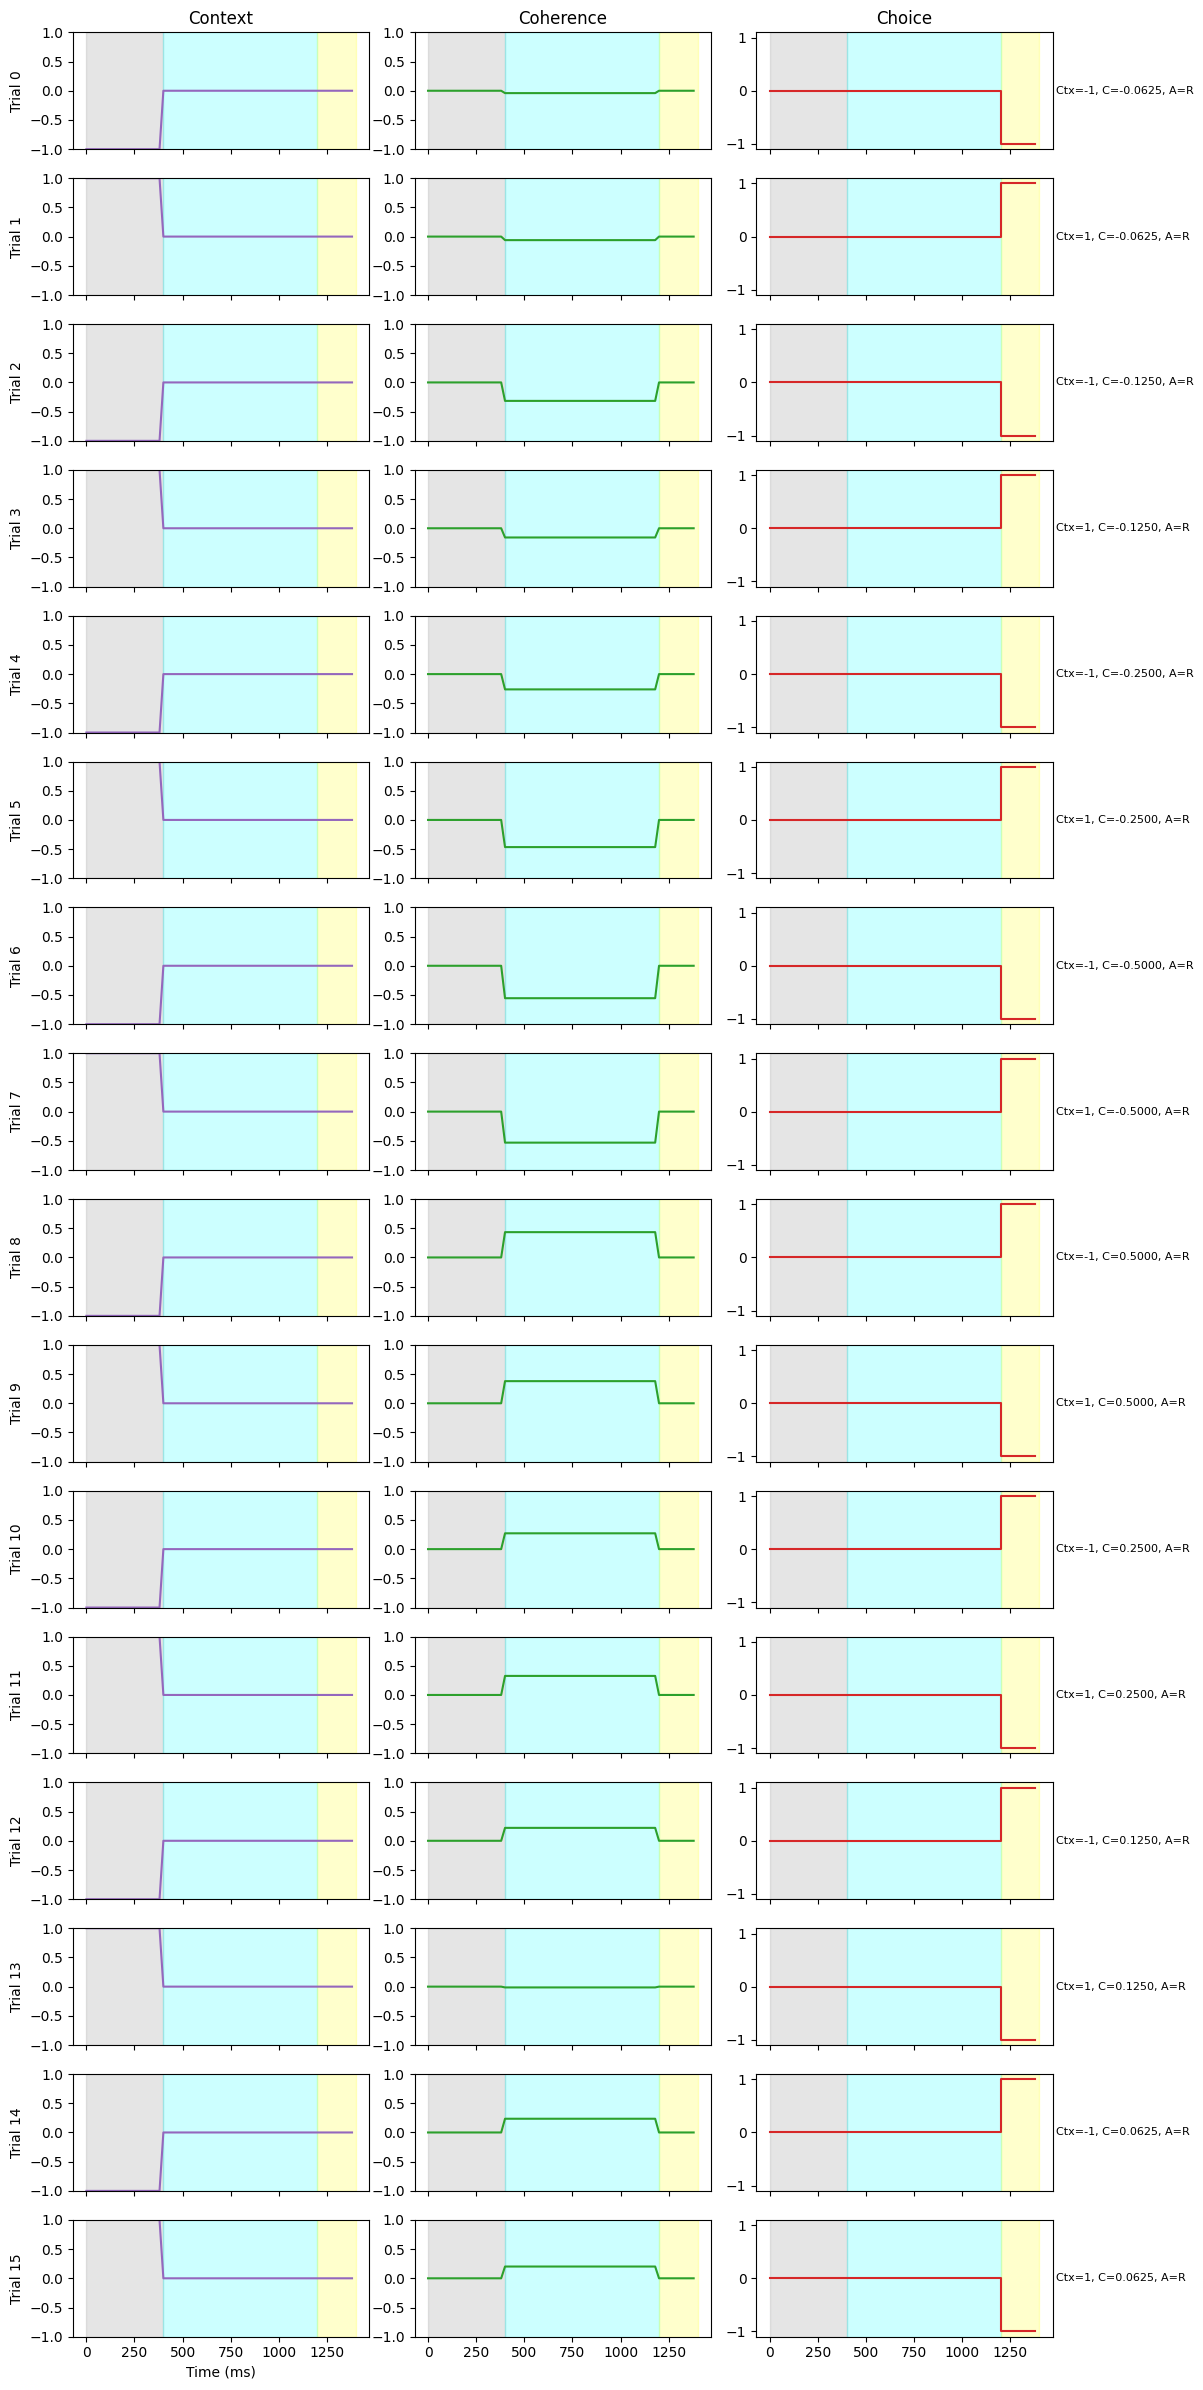

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from math import floor



deltaT = 20.0
t_ctx   = 400    # context cue duration (ms)
t_stim  = 800    # checkerboard stimulus duration (ms)
t_dec   = 200    # decision window (ms)
t_delay = 0      # no delay between stim and decision for simplicity

t_ctx_steps  = floor(t_ctx   / deltaT)
t_stim_steps = floor(t_stim  / deltaT)
t_dec_steps  = floor(t_dec   / deltaT)
t_total      = t_ctx_steps + t_stim_steps + t_dec_steps

pos_vals = 0.5 * (0.5 ** np.arange(0, 4, dtype=float))  
#     pos_vals = [0.5, 0.25, 0.125, 0.0625]


neg_vals = -pos_vals[::-1]  
coherences = np.concatenate([neg_vals, pos_vals])  


print("8 specific coherence：")
print(coherences)
# [-0.5    -0.25   -0.125  -0.0625  0.0625  0.125   0.25    0.5   ]

# make_single_xor_trial：

def make_single_xor_trial(context, coherence, std=0, coh_noise_mean = 0.1,coh_noise_std=0):#idealized
    '''
    context: 0/1
    coherence: float [-1,1] 
    std: 
    coh_noise_std
    
      x: Tensor(1, t_total, 2)  
      y: Tensor(1, t_total, 1)  
      mask: Tensor(1, t_total, 1) 
    '''
    
    x = std * torch.randn(1, t_total, 3)

    
    x[0, :t_ctx_steps, 0] = float(context)

    
    stim_slice = slice(t_ctx_steps, t_ctx_steps + t_stim_steps)
    x[0, stim_slice, 1] = coherence+ coh_noise_mean* torch.randn(1)
    
    x[0, stim_slice, 1] += coh_noise_std * torch.randn(t_stim_steps)
    
    x[0, :, 2] = 1.0  

    # color_choice: 1 if coherence > 0 else 0
    color_choice = 1 if coherence > 0 else 0

   
    if (context == 1 and color_choice == 1) or (context == -1 and color_choice == 0):
        action = -1
    else:
        action = 1

    y = torch.zeros(1, t_total, 1)
    mask = torch.zeros_like(y)
    start = t_ctx_steps + t_stim_steps
    y[0, start:start + t_dec_steps, 0]   = float(action)
    mask[0, start:start + t_dec_steps, 0] = 1.0

    return x, y, mask

def generate_xor_batch(n_trials, std=0.05,coh_noise_mean = 0.05,coh_noise_std=0.05):
    X = torch.zeros(n_trials, t_total, 3)  
    Y = torch.zeros(n_trials, t_total, 1)
    M = torch.zeros_like(Y)
    params = []
    for i in range(n_trials):
        ctx = np.random.choice([-1,1])
        coh = float(np.random.choice(coherences))
        x, y, m = make_single_xor_trial(ctx, coh, std, coh_noise_mean, coh_noise_std)
        X[i], Y[i], M[i] = x, y, m
        params.append((ctx, coh, int(y[0,-1,0])))
    return X, Y, M, params




def plot_multiple_xor(X, Y, params, trial_indices, deltaT,
                      t_ctx_steps, t_stim_steps, t_total):
   
    n = len(trial_indices)
    fig, axes = plt.subplots(n, 3, figsize=(12, n * 1.5), sharex=True)
    t = np.arange(t_total) * deltaT

   
    phases = [
        ('Context', 0, t_ctx_steps, 'gray'),
        ('Stimulus', t_ctx_steps, t_ctx_steps + t_stim_steps, 'cyan'),
        ('Decision', t_ctx_steps + t_stim_steps, t_total, 'yellow')
    ]

    for row, idx in enumerate(trial_indices):
        ctx, coh, action = params[idx]
        ax_ctx, ax_coh, ax_act = axes[row]

       
        ax_ctx.plot(t, X[idx, :, 0].numpy(), color='tab:purple')
        ax_ctx.set_ylim(-1, 1)
        if row == 0:
            ax_ctx.set_title('Context')

        
        ax_coh.plot(t, X[idx, :, 1].numpy(), color='tab:green')
        ax_coh.set_ylim(-1, 1)
        if row == 0:
            ax_coh.set_title('Coherence')

        
        ax_act.step(t, Y[idx, :, 0].numpy(), where='post', color='tab:red')
        ax_act.set_ylim(-1.1, 1.1)
        if row == 0:
            ax_act.set_title('Choice')

        
        for ax in (ax_ctx, ax_coh, ax_act):
            for name, start, end, color in phases:
                ax.axvspan(start * deltaT, end * deltaT, color=color, alpha=0.2)

        
        axes[row, 0].set_ylabel(f'Trial {idx}')
    
        axes[row, 2].annotate(
            f'Ctx={ctx}, C={coh:.4f}, A={"R" if action else "L"}',
            xy=(1.01, 0.5), xycoords='axes fraction',
            va='center', fontsize=8
        )

    
    axes[-1, 0].set_xlabel('Time (ms)')
    plt.tight_layout()
    plt.show()




if __name__ == '__main__':
   
    n_sel = len(coherences) * 2  
    X_sel = torch.zeros(n_sel, t_total, 3)
    Y_sel = torch.zeros(n_sel, t_total, 1)
    M_sel = torch.zeros_like(Y_sel)
    params_sel = []   

    
    idx = 0
    for coh in coherences:
        for ctx in [-1, 1]:
            x, y, m = make_single_xor_trial(ctx, float(coh))
            X_sel[idx] = x
            Y_sel[idx] = y
            M_sel[idx] = m
            
            params_sel.append((ctx, float(coh), int(y[0, -1, 0])))  
            idx += 1

    
    all_indices = list(range(n_sel))  # [0,1,2,...,15]
    plot_multiple_xor(X_sel, Y_sel, params_sel, all_indices,
        deltaT, t_ctx_steps, t_stim_steps, t_total)
    


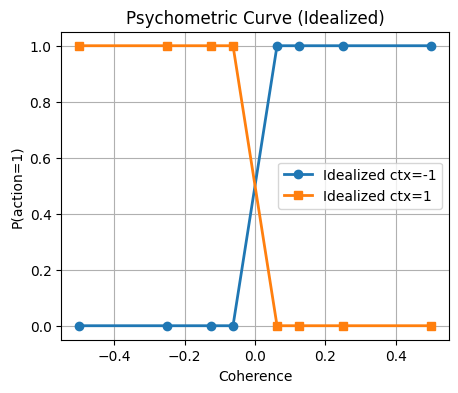

In [3]:
cohs = np.array(coherences)
probs_ctx_neg1 = []
probs_ctx1 = []

for coh in cohs:
    # ctx=-1
    idxs0 = [i for i, p in enumerate(params_sel) if abs(p[1] - coh) < 1e-8 and p[0] == -1]
    if len(idxs0) == 0:
        probs_ctx_neg1.append(np.nan)
    else:
        y_last0 = [Y_sel[i, -1, 0].item() for i in idxs0]
        probs_ctx_neg1.append(np.mean(np.array(y_last0) > 0.5))
    # ctx=1
    idxs1 = [i for i, p in enumerate(params_sel) if abs(p[1] - coh) < 1e-8 and p[0] == 1]
    if len(idxs1) == 0:
        probs_ctx1.append(np.nan)
    else:
        y_last1 = [Y_sel[i, -1, 0].item() for i in idxs1]
        probs_ctx1.append(np.mean(np.array(y_last1) > 0.5))

cohs = np.sort(np.array(coherences))
plt.figure(figsize=(5,4))
plt.plot(cohs, probs_ctx_neg1, 'o-', lw=2, label='Idealized ctx=-1')
plt.plot(cohs, probs_ctx1, 's-', lw=2, label='Idealized ctx=1')
plt.xlabel('Coherence')
plt.ylabel('P(action=1)')
plt.title('Psychometric Curve (Idealized)')
plt.legend()
plt.grid(True)
plt.show()

Training...
initial loss: 0.999
epoch 0:  loss=0.997  (took 3.64 s) *
tensor([1.0000, 0.0383, 1.0000]) input.....
tensor([-1.]) target.....
tensor([[-0.0353],
        [-0.0359],
        [-0.0367],
        [-0.0369],
        [-0.0390]], grad_fn=<SliceBackward0>) output.....
epoch 1:  loss=0.995  (took 3.59 s) *
tensor([-1.0000,  0.0537,  1.0000]) input.....
tensor([1.]) target.....
tensor([[-0.0106],
        [-0.0109],
        [-0.0117],
        [-0.0127],
        [-0.0134]], grad_fn=<SliceBackward0>) output.....
epoch 2:  loss=0.946  (took 3.60 s) *
tensor([ 1.0000, -0.0214,  1.0000]) input.....
tensor([-1.]) target.....
tensor([[-0.1484],
        [-0.1474],
        [-0.1465],
        [-0.1457],
        [-0.1458]], grad_fn=<SliceBackward0>) output.....
epoch 3:  loss=0.774  (took 3.12 s) *
tensor([ 1.0000, -0.0140,  1.0000]) input.....
tensor([-1.]) target.....
tensor([[-0.1323],
        [-0.1341],
        [-0.1333],
        [-0.1320],
        [-0.1336]], grad_fn=<SliceBackward0>) outp

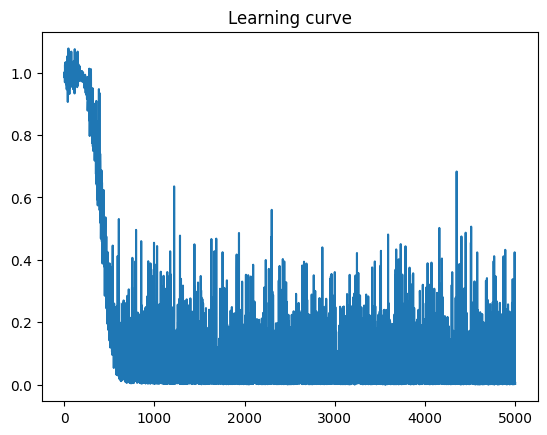

RECURRENT WEIGHT MATRIX:
Parameter containing:
tensor([[ 0.0193, -0.0240,  0.0074,  ..., -0.0043, -0.0070,  0.0961],
        [-0.0240,  0.0367,  0.0424,  ..., -0.0030,  0.0514, -0.0793],
        [ 0.0130, -0.0150, -0.0872,  ...,  0.0221, -0.0051, -0.0219],
        ...,
        [ 0.0131,  0.0111, -0.0620,  ..., -0.0225, -0.0644,  0.0544],
        [ 0.0669, -0.0179,  0.0068,  ...,  0.0035,  0.0422,  0.0488],
        [-0.0379,  0.0249,  0.0096,  ..., -0.0220, -0.0702,  0.0297]],
       requires_grad=True)
Validation Loss: 0.0768, Accuracy: 0.9750


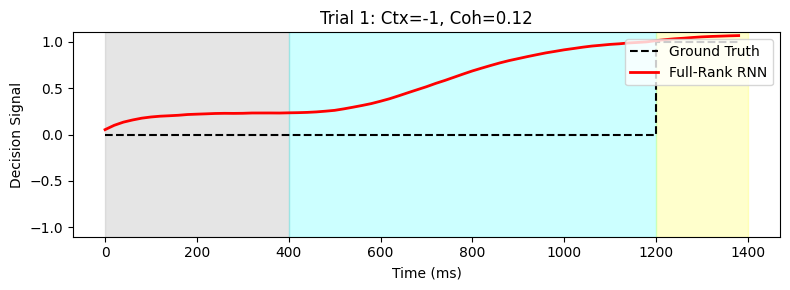

In [ ]:
# Training a Full-Rank RNN on the XOR Task



import torch
import numpy as np
import matplotlib.pyplot as plt
from FullRank import FullRankRNN, loss_mse, train, accuracy_general
from low_rank_rnns.helpers import map_device
from math import floor

deltaT = 20.
t_ctx     = 400
t_stim    = 800
t_dec     = 200
t_ctx_steps  = floor(t_ctx/deltaT)
t_stim_steps = floor(t_stim/deltaT)
t_dec_steps  = floor(t_dec/deltaT)
t_total      = t_ctx_steps + t_stim_steps + t_dec_steps



INPUT_SIZE  = 3      # context + coherence
HIDDEN_SIZE = 512    
OUTPUT_SIZE = 1      
NOISE_STD   = 0.02   
ALPHA       = 0.2#0.05    # dt/tau


net = FullRankRNN(
    input_size=INPUT_SIZE,
    hidden_size=HIDDEN_SIZE,
    output_size=OUTPUT_SIZE,
    noise_std=NOISE_STD,
    alpha=ALPHA,
    
    train_wi=True,
    train_wo=True,
    train_wrec=True,
    train_h0=False,
)


X_all, Y_all, M_all, params_all = generate_xor_batch(n_trials=2000, std=0.05)
split = int(0.8 * X_all.shape[0])
X_tr, X_val = X_all[:split], X_all[split:]
Y_tr, Y_val = Y_all[:split], Y_all[split:]
M_tr, M_val = M_all[:split], M_all[split:]


X_tr, Y_tr, M_tr, X_val, Y_val, M_val = map_device(
    [X_tr, Y_tr, M_tr, X_val, Y_val, M_val], net
)


def run_training():
    train(
        net,
        X_tr, Y_tr, M_tr,
        n_epochs=50,
        lr=1e-5,#1e-2,#
        batch_size=16,#128,
        plot_learning_curve=True,
        plot_gradient=False,
        cuda=torch.cuda.is_available(),
        keep_best=True,
    )
    
    with torch.no_grad():
        out = net(X_val)
        val_loss = loss_mse(out, Y_val, M_val).item()
        val_acc  = accuracy_general(out, Y_val, M_val).item()
        print(f"Validation Loss: {val_loss:.4f}, Accuracy: {val_acc:.4f}")


if __name__ == '__main__':
    run_training()


net.eval()
trial_idx = 1
ctx, coh, _ = params_all[split + trial_idx]
x, y_true, _ = make_single_xor_trial(ctx, coh)
with torch.no_grad():
    y_pred = net(x)[0, :, 0].cpu().numpy()
    y_true = y_true[0, :, 0].numpy()
t = np.arange(t_total) * deltaT

plt.figure(figsize=(8,3))
plt.step(t, y_true, where='post', label='Ground Truth', ls='--', c='k')
plt.plot(t, y_pred, label='Full-Rank RNN', c='r', lw=2)
for name, s, e, color in [
    ('Ctx', 0, t_ctx_steps, 'gray'),
    ('Stim', t_ctx_steps, t_ctx_steps+t_stim_steps, 'cyan'),
    ('Dec', t_ctx_steps+t_stim_steps, t_total, 'yellow'),
]:
    plt.axvspan(s*deltaT, e*deltaT, color=color, alpha=0.2)
plt.xlabel('Time (ms)')
plt.ylabel('Decision Signal')
plt.ylim(-1.1, 1.1)
plt.legend(loc='upper right')
plt.title(f'Trial {trial_idx}: Ctx={ctx}, Coh={coh:.2f}')
plt.tight_layout()
plt.show()


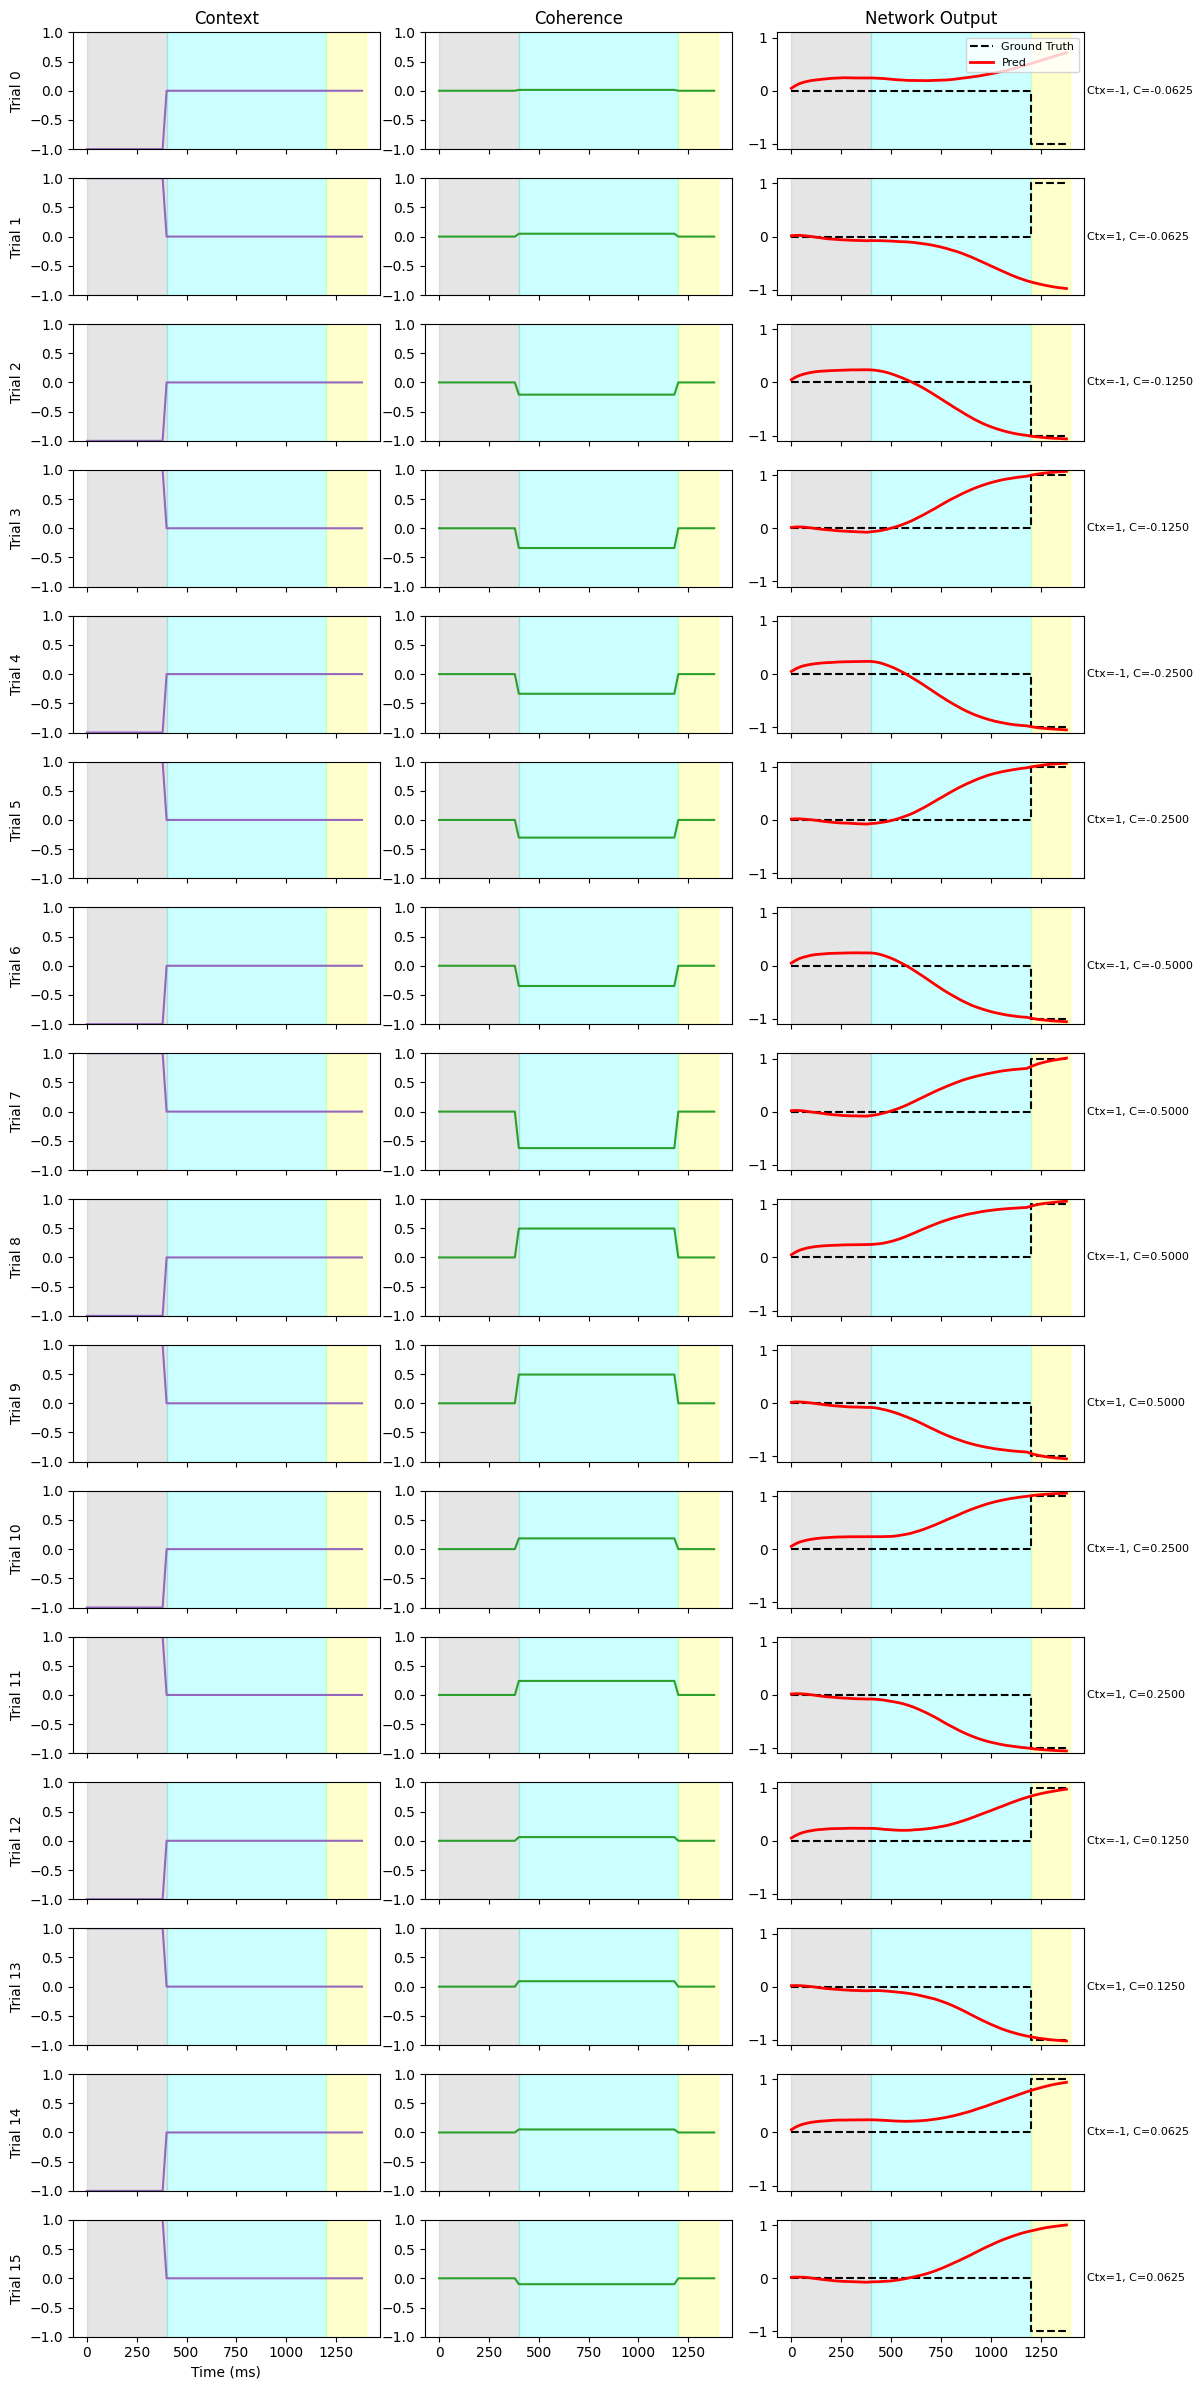

In [ ]:


def plot_multiple_xor_pred(X, Y_true, Y_pred, params, trial_indices, deltaT,
                          t_ctx_steps, t_stim_steps, t_total):
    n = len(trial_indices)
    fig, axes = plt.subplots(n, 3, figsize=(12, n * 1.5), sharex=True)
    t = np.arange(t_total) * deltaT
    phases = [
        ('Context', 0, t_ctx_steps, 'gray'),
        ('Stimulus', t_ctx_steps, t_ctx_steps + t_stim_steps, 'cyan'),
        ('Decision', t_ctx_steps + t_stim_steps, t_total, 'yellow')
    ]
    for row, idx in enumerate(trial_indices):
        ctx, coh, _ = params[idx]
        ax_ctx, ax_coh, ax_act = axes[row]
        ax_ctx.plot(t, X[idx, :, 0].numpy(), color='tab:purple')
        ax_ctx.set_ylim(-1, 1)
        if row == 0: ax_ctx.set_title('Context')
        ax_coh.plot(t, X[idx, :, 1].numpy(), color='tab:green')
        ax_coh.set_ylim(-1, 1)
        if row == 0: ax_coh.set_title('Coherence')
        
        ax_act.step(t, Y_true[idx, :, 0].numpy(), where='post', color='k', linestyle='--', label='Ground Truth')
        ax_act.plot(t, Y_pred[idx], color='r', lw=2, label='Pred')
        ax_act.set_ylim(-1.1, 1.1)
        if row == 0: ax_act.set_title('Network Output')
        for ax in (ax_ctx, ax_coh, ax_act):
            for name, start, end, color in phases:
                ax.axvspan(start * deltaT, end * deltaT, color=color, alpha=0.2)
        axes[row, 0].set_ylabel(f'Trial {idx}')
        axes[row, 2].annotate(
            f'Ctx={ctx}, C={coh:.4f}',
            xy=(1.01, 0.5), xycoords='axes fraction',
            va='center', fontsize=8
        )
        if row == 0:
            ax_act.legend(loc='upper right', fontsize=8)
    axes[-1, 0].set_xlabel('Time (ms)')
    plt.tight_layout()
    plt.show()


n_sel = len(coherences) * 2
X_sel = torch.zeros(n_sel, t_total, 3)
Y_sel = torch.zeros(n_sel, t_total, 1)
params_sel = []
idx = 0
for coh in coherences:
    for ctx in [-1, 1]:
        x, y, _ = make_single_xor_trial(ctx, float(coh))
        X_sel[idx] = x
        Y_sel[idx] = y
        params_sel.append((ctx, float(coh), int(y[0, -1, 0])))
        idx += 1


net.eval()
with torch.no_grad():
    Y_pred = net(X_sel).cpu().numpy()[:, :, 0]


plot_multiple_xor_pred(X_sel, Y_sel, Y_pred, params_sel, list(range(n_sel)),
                       deltaT, t_ctx_steps, t_stim_steps, t_total)

coh -0.5
coh -0.25
coh -0.125
coh -0.0625
coh 0.0625
coh 0.125
coh 0.25
coh 0.5


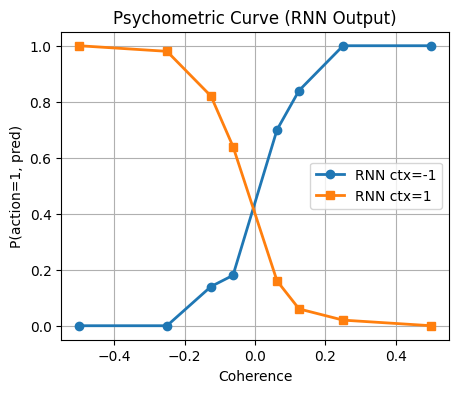

In [ ]:


import numpy as np
import matplotlib.pyplot as plt

n_rep = 50  
cohs = np.sort(coherences)
probs_pred_ctx_neg1 = []
probs_pred_ctx1 = []

for coh in cohs:
    # ctx = -1
    outs0 = []
    for _ in range(n_rep):
        x, _, _ = make_single_xor_trial(-1, coh, std=0.05, coh_noise_std=0.05)
        with torch.no_grad():
            y_pred = net(x).cpu().numpy()[0, -1, 0]  
        outs0.append(y_pred > 0.5)  
    probs_pred_ctx_neg1.append(np.mean(outs0))

    # ctx = 1
    outs1 = []
    print('coh',coh)
    for _ in range(n_rep):
        x, _, _ = make_single_xor_trial(1, coh, std=0.05,coh_noise_std=0.05)
        with torch.no_grad():
            y_pred = net(x).cpu().numpy()[0, -1, 0]
        outs1.append(y_pred > 0.5)
    probs_pred_ctx1.append(np.mean(outs1))
    
cohs = np.sort(np.array(coherences))
plt.figure(figsize=(5,4))
plt.plot(cohs, probs_pred_ctx_neg1, 'o-', lw=2, label='RNN ctx=-1')
plt.plot(cohs, probs_pred_ctx1, 's-', lw=2, label='RNN ctx=1')
plt.xlabel('Coherence')
plt.ylabel('P(action=1, pred)')
plt.title('Psychometric Curve (RNN Output)')
plt.legend()
plt.grid(True)
plt.show()

In [9]:
# Extract parameters from the trained network
W_rec = net.wrec.detach().cpu().numpy()
W_in  = net.wi_full.detach().cpu().numpy()
W_out = net.wo_full.detach().cpu().numpy()
alpha = net.alpha
noise_std = net.noise_std
nonlinearity = np.tanh 

def simulate_rnn_dynamics(W_rec, W_in, W_out, alpha, nonlinearity, x_seq, h0=None, noise_std=0.0):
    """
    Simulate the RNN dynamics in numpy for analysis.
    x_seq: shape (T, input_dim)
    h0: initial hidden state, shape (hidden_dim,)
    Returns: h_seq (T, hidden_dim), r_seq (T, hidden_dim), y_seq (T, output_dim)
    """
    T, input_dim = x_seq.shape
    hidden_dim = W_rec.shape[0]
    output_dim = W_out.shape[1]
    h_seq = np.zeros((T, hidden_dim))
    r_seq = np.zeros((T, hidden_dim))
    y_seq = np.zeros((T, output_dim))
    h = np.zeros(hidden_dim) if h0 is None else h0.copy()
    for t in range(T):
        noise = np.random.randn(hidden_dim) * noise_std
        r = nonlinearity(h)
        h = h + noise + alpha * (-h + r @ W_rec.T + x_seq[t] @ W_in)
        y = r @ W_out
        h_seq[t] = h
        r_seq[t] = r
        y_seq[t] = y
    return h_seq, r_seq, y_seq


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401
from matplotlib.lines import Line2D


t_total = t_ctx_steps + t_stim_steps + t_dec_steps



def collect_hidden_trajectories_by_ctx_coh_sign(net, params_sel, t_total):
    
    W_rec = net.wrec.detach().cpu().numpy()
    W_in  = net.wi_full.detach().cpu().numpy()
    alpha = net.alpha
    noise = net.noise_std
    H = W_rec.shape[0]

    # coherences
    pos_cohs = [c for c in coherences if c > 0]
    neg_cohs = [c for c in coherences if c < 0]

    conditions = [
        (-1, 'pos'),  # ctx=0, coh>0
        (-1, 'neg'),  # ctx=0, coh<0
        (1, 'pos'),  # ctx=1, coh>0
        (1, 'neg'),  # ctx=1, coh<0
    ]
    all_r_mean = np.zeros((4, t_total, H), dtype=np.float32)
    params = []

    for i, (ctx, sign) in enumerate(conditions):
        
        if sign == 'pos':
            coh_set = pos_cohs
        else:
            coh_set = neg_cohs
        
        idxs = [j for j, (c, coh, _) in enumerate(params_sel)
                if c == ctx and coh in coh_set]
        r_list = []
        actions = []
        for j in idxs:
            coh = float(params_sel[j][1])
            x, _, _ = make_single_xor_trial(ctx, coh)
            x_seq = x.squeeze(0).cpu().numpy()
            h = np.zeros(H, dtype=np.float32)
            r_traj = np.zeros((t_total, H), dtype=np.float32)
            for t in range(t_total):
                r = np.tanh(h)
                h = h + np.random.randn(H).astype(np.float32) * noise + alpha * (
                    -h + W_rec.dot(r) + x_seq[t].dot(W_in)
                )
                r_traj[t] = r
            r_list.append(r_traj)
            with torch.no_grad():
                y_pred = net(x).cpu().numpy()[0, -1, 0]
                actions.append(int(y_pred > 0.6))
        if len(r_list) > 0:
            all_r_mean[i] = np.mean(np.stack(r_list, axis=0), axis=0)
            action_mean = np.mean(actions)
        else:
            all_r_mean[i] = np.nan
            action_mean = np.nan
        params.append((ctx, sign, action_mean))
    return all_r_mean, params


def flatten_trials(all_r_mean):
    
    N, T, H = all_r_mean.shape
    X = all_r_mean.reshape(N * T, H)
    return X

def run_pca(all_r_mean, n_components=3):
    """
    PCA 降维：all_r (N, T, H) → Z_trials (N, T, 3)
    """
    N, T, H = all_r_mean.shape
    X = flatten_trials(all_r_mean)  # shape: (N*T, H)
    pca = PCA(n_components=n_components)
    Z = pca.fit_transform(X)  # (N*T, n_components)
    print("Explained variance ratios:", pca.explained_variance_ratio_)
    Z_trials = Z.reshape(N, T, n_components)
    return Z_trials, pca

all_r_mean, mean_params = collect_hidden_trajectories_by_ctx_coh_sign(
    net, params_sel, t_total)
Z_trials, pca = run_pca(all_r_mean, n_components=3)

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


def plot_pca_by_color_action(Z_trials, params, t_ctx_steps, t_stim_steps, t_total,
                             elev=30, azim=45):
    """
    Z_trials: (4, t_total, 3)
    params:   list of 4 tuples (ctx, coh, action)  
              ctx in {0,1}, coh in {-0.5,0.5}, action in {0,1}
    """
    fig = plt.figure(figsize=(6,6))
    ax  = fig.add_subplot(111, projection='3d')
    
    for traj, (ctx, coh, action) in zip(Z_trials, params):
        k1, k2, k3 = traj[:,0], traj[:,1], traj[:,2]

        
        t0 = 0
        t1 = t_ctx_steps
        t2 = t_ctx_steps + t_stim_steps
        t3 = t_total

        
        ctx_ls = '-' if ctx == 1 else '--'
        dec_color = dec_color = 'red' if action > 0.5 else 'green'
        
        ax.plot(k1[t0:t1+1], k2[t0:t1+1], k3[t0:t1+1],
                color=dec_color, linestyle=ctx_ls, linewidth=2)

        
        ax.plot(k1[t1:t2+1], k2[t1:t2+1], k3[t1:t2+1],
                color=dec_color, linestyle=ctx_ls, linewidth=2)

       
        
        ax.plot(k1[t2:t3], k2[t2:t3], k3[t2:t3],
                color=dec_color, linestyle=ctx_ls, linewidth=2)

        
        ax.scatter(k1[t0], k2[t0], k3[t0],
                   marker='o', color='k',   s=60)            # Target Onset
        ax.scatter(k1[t1], k2[t1], k3[t1],
                   marker='^', color='magenta', s=60, edgecolor='k')  # Checkerboard
        ax.scatter(k1[t3-1], k2[t3-1], k3[t3-1],
                   marker='*', color=dec_color, s=100)       # Decision End

    
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_zlabel('PC3')
    ax.view_init(elev=elev, azim=azim)

    
    legend_elems = [
        Line2D([0],[0], color='k',      ls='-',  lw=2, label='Context ctx=1'),
        Line2D([0],[0], color='k',      ls='--', lw=2, label='Context ctx=-1'),
        Line2D([0],[0], color='red',    lw=2, label='Decision action=1'),
        Line2D([0],[0], color='green',  lw=2, label='Decision action=-1'),
        Line2D([0],[0], marker='o', color='k', linestyle='None', markersize=8, label='Target Onset'),
        Line2D([0],[0], marker='^', color='magenta', linestyle='None', markersize=8, label='Checker Onset'),
        Line2D([0],[0], marker='*', color='black',   linestyle='None', markersize=10, label='Decision End'),
    ]
    ax.legend(handles=legend_elems, bbox_to_anchor=(1.05,1), loc='upper left')
    plt.tight_layout()
    plt.show()
    fig.suptitle('Neural State Trajectories in PC Space\n(XOR Task -1/+1 fixation)', 
                 fontsize=14, fontweight='bold', y=0.95)

%matplotlib qt5
plot_pca_by_color_action(Z_trials, mean_params,t_ctx_steps, t_stim_steps, t_total)


Explained variance ratios: [0.5054495  0.21495236 0.12248368]


In [ ]:
def velocity_field_with_input(hidden_init, Umat, x_t,pca_remains,n_grid):
    
    velocity = np.zeros((np.shape(hidden_init)[0], 2))
    for i in range(np.shape(hidden_init)[0]):
        init_pc12 = np.squeeze(hidden_init[i,:])

        pts_merge = np.concatenate((init_pc12, pca_remains), axis=0)

        
        r = pts_merge.dot(Umat)            # (M,H)
        if np.abs(r).max() > 1:
            r = np.clip(r, -0.999, 0.999)
        h = np.arctanh(r)
        # h = pts_merge.dot(Umat)  #(M,H)
        # r = np.tanh(h)                # (M,H)
        
        #    dh = -h + W_rec·r + W_in·x_t
        #    W_rec·r^T = r.dot(W_rec.T)
        #    W_in·x_t = x_t.dot(W_in)  gives (H,)
        dh = -h + r.dot(W_rec.T) + x_t.dot(W_in)
        #  Euler 
        h_new = h + alpha * dh
        r_new = np.tanh(h_new)
        #  dr = r_new - r
        dr = r_new - r               # (M,H)
        # dr·Umat^T → (M,3)
        v_pc = dr.dot(Umat.T)        # (M,3)
        velocity[i, :] = v_pc[:2]
    # 
    U = velocity[:,0].reshape(n_grid,n_grid)
    V = velocity[:,1].reshape(n_grid,n_grid)
    # velocity = v_pc[:, :2].reshape(n_grid, n_grid, 2).transpose(2,0,1)
    return U, V

In [ ]:
_, pca_full = run_pca(all_r_mean, n_components=280)
conds = [(-1, 0.5), (-1, -0.5)]

x_seqs = []
for ctx, coh in conds:
    x, _, _ = make_single_xor_trial(ctx, coh, std=0.0,coh_noise_std=0.0)
    x_seqs.append(x.squeeze(0).cpu().numpy())
    h0, r0, y0 = simulate_rnn_dynamics(W_rec, W_in, W_out, alpha, nonlinearity, x_seqs[0], h0=None, noise_std=0.0)
    r0_pca = pca_full.transform(r0)  # (t_total, 3)


r0_pca = pca.transform(r0)  # (1, 3)
init_pc12 = np.array([r0_pca[0, 0], r0_pca[0, 1]])
pca_remains = r0_pca[0,2:]
pca_merge = np.concatenate((init_pc12, pca_remains), axis=0)

# 1) 
N, T, H = all_r_mean.shape
X_flat = all_r_mean.reshape(N * T, H)            # (4*t_total, H)

# 2) 
Z_flat = pca_full.transform(X_flat)               # (4*t_total, n_components)

# 3) 
Z_trials_full = Z_flat.reshape(N, T, -1)          # (4, t_total, n_components)           


r0_pca[t_total-1,2]

Explained variance ratios: [5.05449355e-01 2.14952454e-01 1.22483663e-01 6.26611635e-02
 3.78346853e-02 1.92926582e-02 1.10022882e-02 6.73532858e-03
 3.91233852e-03 3.28993145e-03 2.71596946e-03 2.58261943e-03
 2.05745688e-03 1.27220689e-03 7.40849297e-04 5.06068929e-04
 4.48431761e-04 4.22938960e-04 2.83917267e-04 2.81005952e-04
 1.77852970e-04 1.59900097e-04 1.08656437e-04 9.72052585e-05
 7.46267033e-05 5.63948488e-05 4.47025814e-05 3.79958110e-05
 3.04718160e-05 2.66817915e-05 2.08756064e-05 1.64796838e-05
 1.39585527e-05 1.21348057e-05 1.13434126e-05 9.85140196e-06
 8.61467834e-06 8.53983147e-06 7.60630155e-06 6.93287620e-06
 6.59647412e-06 5.82020084e-06 5.69324857e-06 5.27100428e-06
 4.73382988e-06 4.28594603e-06 4.26325732e-06 3.88585613e-06
 3.62143805e-06 3.42148860e-06 3.25685937e-06 3.23100835e-06
 2.82715087e-06 2.62353683e-06 2.49597429e-06 2.29265152e-06
 2.08170400e-06 1.95779921e-06 1.91855452e-06 1.85634826e-06
 1.79755739e-06 1.70861779e-06 1.63522191e-06 1.61064906e-

np.float64(3.085763256425782)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt


t_total = t_ctx_steps + t_stim_steps + t_dec_steps
alpha   = 0.1  # dt/tau
mid_ctx = t_ctx_steps-5
mid_stim= t_ctx_steps -10 + t_stim_steps//2 

all_k1 = Z_trials[:,:,0].ravel()
all_k2 = Z_trials[:,:,1].ravel()
k1_min, k1_max = -15,15
k2_min, k2_max = -15,15

n_grid = 25
xx, yy = np.meshgrid(
    np.linspace(k1_min, k1_max, n_grid),
    np.linspace(k2_min, k2_max, n_grid)
)
hidden_grid_2d = np.vstack((xx.flatten(),  yy.flatten())).T
hidden_init = np.zeros((hidden_grid_2d.shape[0], 2))
hidden_init[:,:] = hidden_grid_2d


W_rec = net.wrec.detach().cpu().numpy()
W_in  = net.wi_full.detach().cpu().numpy()   # shape (2, H)
Umat  = pca_full.components_                     # shape (3, H)
W_out = net.wo_full.detach().cpu().numpy()
alpha = net.alpha
noise_std = net.noise_std
nonlinearity = np.tanh 


conds = [(-1, -0.5), (-1, 0.5), (1, -0.5), (1, 0.5)]
x_seqs = []
rpca_seqs = []
for ctx, coh in conds:
    x, _, _ = make_single_xor_trial(ctx, coh, std=0.0, coh_noise_mean = 0.0,coh_noise_std=0.0)
    x0 = x.squeeze(0).cpu().numpy()  # shape (t_total, 2)
    x_seqs.append(x0)  # shape (t_total, 2)
    h0, r0, y0 = simulate_rnn_dynamics(W_rec, W_in, W_out, alpha, nonlinearity, x0, h0=None, noise_std=0.0)
    r0_pca = pca_full.transform(r0)  # (t_total, 3)
    rpca_seqs.append(r0_pca)  # shape (t_total, 3)


fig, axes = plt.subplots(2,2, figsize=(10,10), sharex=True, sharey=True)
titles = ['Config1 coh<0','Config1 coh>0','Config2 coh<0','Config2 coh>0']
coh_color = { 0.5: 'tab:red', -0.5: 'tab:green' }

for ax, idx, title in zip(axes.ravel(), range(4), titles):
    
    ctx, coh = conds[idx]

   
    x, _, _ = make_single_xor_trial(ctx, coh, std=0.0, coh_noise_std=0.0)
    with torch.no_grad():
        action = int((net(x)[0,-1,0].cpu().numpy()) > 0.5)

    
    x_t = x_seqs[idx][mid_stim]         
    pc3 = rpca_seqs[idx][mid_stim-1,2:]    
    # print(pc3,'-------')
    U, V = velocity_field_with_input(hidden_init, Umat, x_t,pc3,n_grid)

   
    
    speed = np.sqrt(U**2 + V**2)
    pcm = ax.pcolormesh(xx, yy, speed, shading='auto', cmap='plasma')
    ax.streamplot(xx, yy, U, V, color='white', density=1.0, linewidth=0.6)
    
    
    traj = rpca_seqs[idx]  # (t_total, 3)
    k1 = traj[:,0]; k2 = traj[:,1]
    t0 = 0
    t1 = t_ctx_steps
    t2 = t_ctx_steps + t_stim_steps
    t3 = t_total

    
    ls = '-' if ctx == 1 else '--'
    dec_color = 'red' if action == 1 else 'green'
    # 1) 
    ax.plot(k1[t0:t1+1], k2[t0:t1+1],
            color=dec_color, linestyle=ls, linewidth=2)

    # 2) 
    stim_color = 'red' if action == 1 else 'green'
    ax.plot(k1[t1:t2+1], k2[t1:t2+1],
            color=dec_color, linestyle=ls, linewidth=2)

    dec_color = 'red' if action == 1 else 'green'
    ax.plot(k1[t2:t3], k2[t2:t3],
            color=dec_color, linestyle=ls, linewidth=2)
    
   
    ax.scatter(k1[t0], k2[t0], color='k',   s=60, label='Target Onset')
   
    # ax.scatter(k1[t0], k2[t0], 
    #                marker='o', color='k',   s=60)            # Target Onset
    ax.scatter(k1[t1], k2[t1],
                   marker='^', color='magenta', s=60, edgecolor='k',label='Checkerboard Onset')  # Checkerboard
    ax.scatter(k1[mid_stim],k2[mid_stim],s=50,marker='s',color='white',edgecolor='k',label='ctx Mid')
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(title)
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')

# colorbar & legend
# fig.colorbar(pcm, ax=axes.ravel().tolist(), label='Activity velocity in PC space')
axes[0,0].legend(loc='upper right')
plt.suptitle('Fig. 2D – Velocity & 3‑segment Trajectories -1/+1 onehot', y=0.93)
plt.tight_layout()
plt.show()
